### LOSO Analysis
#### Reesink Lab
##### LOSO analysis for Human, Dog, and Horse
README.md for full details

### STEP 1: Load packages and set seed

In [1]:
import pandas as pd
import numpy as np
import re
from pycaret.classification import *
from sklearn.model_selection import StratifiedGroupKFold
import shap
import matplotlib.pyplot as plt
from pycaret.classification import plot_model
from pycaret.classification import get_config
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, auc, precision_recall_curve, 
                             average_precision_score, classification_report)
from sklearn.metrics import roc_auc_score, recall_score, precision_score
from sklearn.model_selection import cross_val_predict
from sklearn.base import clone
SEED = 42
# 3-fold grouped CV was used instead of 5-fold
# to ensure adequate minority-class representation in each fold 
# as a result, 3-fold performed better than 5-fold in LOSO only
sgkf = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)


### STEP 2: Upload dataset

In [2]:
# Step 2a: Upload full dataset
# Upload df
df = pd.read_csv("OAcombined.csv")

# Strip whitespace from column names — several lectin names have trailing spaces
df.columns = df.columns.str.strip()

print(df.shape)
print(df['Condition'].value_counts())
print(df['Species'].value_counts())
print(pd.crosstab(df['Species'], df['Condition']))
print(df.isnull().sum().sum())

(223, 71)
Condition
OA         163
Healthy     60
Name: count, dtype: int64
Species
Horse    118
Dog       59
Human     46
Name: count, dtype: int64
Condition  Healthy  OA
Species               
Dog              9  50
Horse           41  77
Human           10  36
0


In [3]:
# Step 2b: Derive paired human nums from data
human = df[df['Species'] == 'Human'].copy()
human['num'] = human['samples'].str.extract(r'(\d+)')
paired_human_nums = set(
    human.groupby('num')['Condition'].nunique().loc[lambda s: s > 1].index
)
print(f"Paired human nums: {paired_human_nums}")  # verify matches your hardcoded set

def build_subject_id(row):
    idx = row['samples'].strip()
    species = row['Species']
    if species == 'Human':
        num = re.search(r'\d+', idx).group()
        return f"Human_paired_{num}" if num in paired_human_nums else f"Human_OA_{num}"
    return f"{species}_{idx}"

df['subject_id'] = df.apply(build_subject_id, axis=1)
df.head()

Paired human nums: {'17', '9', '8', '19', '23', '21', '12', '11', '18', '10'}


,samples,Condition,Species,SNA-I-EY,SNA-Vector,AMA-Vector,BPL-Vector,MAA-I -Vector,MAA-I,MAA-I-EY,...,Anti Lewis B-Abcam,Anti Lewis A-Abcam,Anti Lewis A-Sigma,Anti B.G.A-Thermo Fisher,Anti PolySia-Absolute Antibody,Anti Sialyl Lewis X,Anti Ficolin-1,Anti Ficolin-3,Anti Galectin 3-Abcam,subject_id
0,Cain 28,Healthy,Dog,1.815339,2.268996,2.179894,0.649467,0.825203,2.532651,2.359761,...,0.840203,2.222272,1.947009,0.303935,-0.679793,0.872960,-2.289926,-1.815454,-0.247574,Dog_Cain 28
1,Cain 30,Healthy,Dog,1.366019,1.714304,0.924740,0.990047,1.601047,1.134314,0.910973,...,1.817118,0.975192,1.827970,-1.308913,-0.789952,1.400459,-2.966817,-4.519325,-0.711100,Dog_Cain 30
2,Cain 67,Healthy,Dog,1.077778,1.756936,1.255054,1.117901,0.558092,1.289017,1.104330,...,0.997390,0.699689,0.043058,-1.609884,-0.825041,1.026786,-5.373881,-5.577203,-1.250851,Dog_Cain 67
3,Cain 27,Healthy,Dog,1.499619,2.999917,3.986378,1.262139,0.685275,1.799894,1.226725,...,1.170677,0.447057,0.436092,-1.985036,-1.485617,0.205815,-6.306169,-5.555920,-0.615316,Dog_Cain 27
4,Cain 68,Healthy,Dog,1.725805,1.998013,2.286434,1.090485,1.469428,2.508723,1.111176,...,1.131852,1.130282,0.893956,-3.193443,0.333147,1.313436,-2.307433,-2.937280,-0.188276,Dog_Cain 68


### STEP 3: Starting point for reviewers (make sure to load libraries)

#### Step 3a: LOSO Horse 

In [4]:
# LOSO for Horse
# Filter horse subjects — train on Dog + Human, evaluate on all Horse
# I chose to use 80/20 split to maximize training since it will be tested just on horse subjects
train_subset_eq = df[df['Species'] != 'Horse'].reset_index(drop=True)
eval_subset_eq = df[df['Species'] == 'Horse'].reset_index(drop=True)
train_groups_eq = train_subset_eq['subject_id']

# Assert target species is fully excluded
assert 'Horse' not in train_subset_eq['Species'].values, "LEAKAGE: Horse in training"
assert set(train_subset_eq['subject_id']) & set(eval_subset_eq['subject_id']) == set(), \
    "Subject overlap between train and eval"

print(f"Train set: {len(train_subset_eq)} samples (excluded Horse)")
print(f"Eval set: {len(eval_subset_eq)} samples (Horse only)\n")

# PyCaret setup — NO test_data, Horse never enters the pipeline
setup(
    data=train_subset_eq,
    target='Condition',
    session_id=SEED,
    index=True,
    normalize=True,
    normalize_method='zscore',
    transformation=False,
    fix_imbalance=True,
    fix_imbalance_method='smote',
    fold_strategy=sgkf,
    fold=5,
    fold_groups=train_groups_eq,
    ignore_features=['subject_id','Species','samples'],
    remove_outliers=False,
    n_jobs=-1,
    verbose=True,
    train_size=0.8
)
compare_models(sort='AUC', n_select=3, verbose=True)

Train set: 105 samples (excluded Horse)
Eval set: 118 samples (Horse only)



,Description,Value
0,Session id,42
1,Target,Condition
2,Target type,Binary
3,Target mapping,"Healthy: 0, OA: 1"
4,Original data shape,"(105, 72)"
5,Transformed data shape,"(159, 69)"
6,Transformed train set shape,"(138, 69)"
7,Transformed test set shape,"(21, 69)"
8,Ignore features,3
9,Numeric features,68


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
knn,K Neighbors Classifier,0.7966,0.8884,0.7966,0.8701,0.8134,0.4666,0.5150,0.2800
et,Extra Trees Classifier,0.8336,0.8658,0.8336,0.8047,0.7923,0.2293,0.2664,0.0400
rf,Random Forest Classifier,0.8570,0.8462,0.8570,0.8465,0.8462,0.4667,0.4777,0.0433
lightgbm,Light Gradient Boosting Machine,0.7995,0.8203,0.7995,0.8150,0.8031,0.3410,0.3515,0.2967
gbc,Gradient Boosting Classifier,0.7987,0.8130,0.7987,0.8407,0.7977,0.4050,0.4429,0.0433
ada,Ada Boost Classifier,0.8106,0.7256,0.8106,0.8196,0.8093,0.3465,0.3610,0.2767
nb,Naive Bayes,0.7966,0.6718,0.7966,0.8524,0.7859,0.2996,0.3731,0.2733
lda,Linear Discriminant Analysis,0.7502,0.6561,0.7502,0.8243,0.7739,0.3414,0.3664,0.0100
lr,Logistic Regression,0.7740,0.6395,0.7740,0.7995,0.7798,0.2896,0.3053,0.5733
svm,SVM - Linear Kernel,0.7621,0.6148,0.7621,0.7968,0.7704,0.2718,0.2903,0.2733


[KNeighborsClassifier(algorithm='auto', leaf_size=30, metric='minkowski',
                      metric_params=None, n_jobs=-1, n_neighbors=5, p=2,
                      weights='uniform'),
 ExtraTreesClassifier(bootstrap=False, ccp_alpha=0.0, class_weight=None,
                      criterion='gini', max_depth=None, max_features='sqrt',
                      max_leaf_nodes=None, max_samples=None,
                      min_impurity_decrease=0.0, min_samples_leaf=1,
                      min_samples_split=2, min_weight_fraction_leaf=0.0,
                      monotonic_cst=None, n_estimators=100, n_jobs=-1,
                      oob_score=False, random_state=42, verbose=0,
                      warm_start=False),
 RandomForestClassifier(bootstrap=True, ccp_alpha=0.0, class_weight=None,
                        criterion='gini', max_depth=None, max_features='sqrt',
                        max_leaf_nodes=None, max_samples=None,
                        min_impurity_decrease=0.0, min_samples_

#### Step 3b: Create and tune models

In [5]:
#Step 3b: Create and tune models
rf_eq = create_model('rf', groups=train_groups_eq)
#Default hyperparameters used throughout; 
#tuned_rf_eq = tune_model(rf_eq,
    #optimize='AUC',
    #n_iter=5,
    #search_library='scikit-optimize',
    #search_algorithm='bayesian',
    #choose_better=True, groups=train_groups_eq)

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.8148,0.7262,0.8148,0.7963,0.7901,0.3478,0.3780
1,0.8276,0.8958,0.8276,0.8145,0.8198,0.3439,0.3469
2,0.9286,0.9167,0.9286,0.9286,0.9286,0.7083,0.7083
Mean,0.8570,0.8462,0.8570,0.8465,0.8462,0.4667,0.4777
Std,0.0509,0.0853,0.0509,0.0585,0.0595,0.1709,0.1636


#### Step 3c: 0.9 Sensitivity-fixed operating point thresholding (out-of-fold)

In [7]:
# Step 3c: Sensitivity-fixed threshold from grouped OOF predictions — Horse LOSO
pipeline = get_config('pipeline')
full_pipeline = clone(pipeline)
full_pipeline.steps.append(('clf', clone(rf_eq)))

ignore_cols = ['subject_id', 'samples', 'Species', 'Condition']
X_all = train_subset_eq.drop(columns=ignore_cols).reset_index(drop=True)
y_all = train_subset_eq['Condition'].reset_index(drop=True)
g_all = train_subset_eq['subject_id'].reset_index(drop=True)

# Alignment checks
assert len(X_all) == len(y_all) == len(g_all) == 105
assert X_all.index.equals(y_all.index) and y_all.index.equals(g_all.index)
assert g_all.notna().all()
assert list(X_all.columns) == list(get_config('X_train').columns), "Feature columns differ from setup()"

# Build folds once; the same folds are used for the checks and the predictions
folds = list(sgkf.split(X_all, y_all, groups=g_all))

# Leakage checks on the folds actually used
validation_count = np.zeros(len(X_all), dtype=int)
for k, (tr, va) in enumerate(folds, start=1):
    overlap = set(g_all.iloc[tr]) & set(g_all.iloc[va])
    assert not overlap, f"Subject leakage in fold {k}: {overlap}"
    validation_count[va] += 1
assert np.all(validation_count == 1), "Each sample must be validated exactly once"

paired = g_all[g_all.str.contains('paired')].unique()
assert len(paired) == 10, f"Expected 10 paired subjects, found {len(paired)}"
print("Pipeline steps:", [n for n, _ in full_pipeline.steps])

# OOF predictions: full pipeline (impute -> SMOTE -> normalize -> RF) refit inside each fold
oof_proba = cross_val_predict(full_pipeline, X_all, y_all, cv=folds, method='predict_proba')
oa_col = list(np.unique(y_all)).index('OA')
oof_scores = oof_proba[:, oa_col]

# Threshold: highest threshold with OOF sensitivity >= 0.90 (maximizes specificity under the floor)
fpr, tpr, thresholds = roc_curve(y_all, oof_scores, pos_label='OA', drop_intermediate=False)
valid = tpr >= 0.90
if not valid.any():
    raise ValueError("No threshold achieves 0.90 sensitivity")
idx = np.argmax(valid)
chosen_threshold_eq = float(thresholds[idx])

# Verify directly against labels
pred = oof_scores >= chosen_threshold_eq
is_oa = (y_all == 'OA').values
sens = pred[is_oa].mean()
spec = (~pred[~is_oa]).mean()
assert sens >= 0.90, f"Sensitivity floor violated: {sens}"
assert np.isclose(sens, tpr[idx]), "Threshold and labels disagree"

print("OOF AUC:", auc(fpr, tpr))
print("Threshold:", chosen_threshold_eq)
print("OOF sensitivity:", sens)
print("OOF specificity:", spec)
print("Step 3c verified.")

Pipeline steps: ['label_encoding', 'numerical_imputer', 'categorical_imputer', 'balance', 'normalize', 'clean_column_names', 'clf']
OOF AUC: 0.8304773561811505
Threshold: 0.57
OOF sensitivity: 0.9186046511627907
OOF specificity: 0.631578947368421
Step 3c verified.


#### Step 3d: SHAP plot

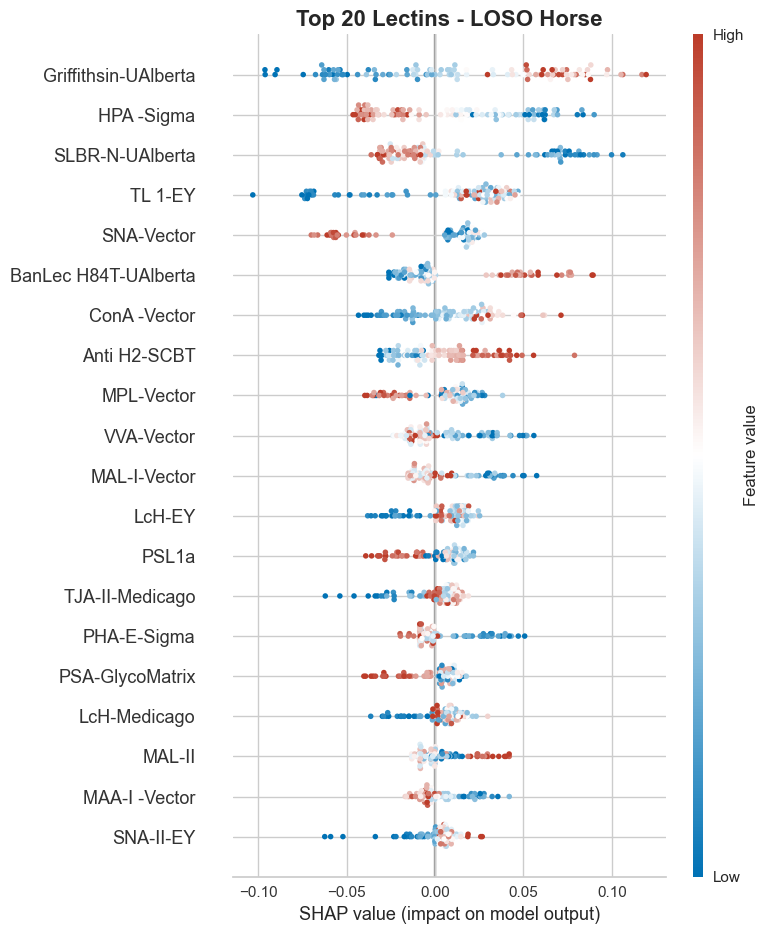

In [8]:
# Step 3d: SHAP plot
# 1. Get the transformed data, filtered to real rows only (no SMOTE synthetic rows)
X_train_transformed = get_config('X_train_transformed')
X_real = X_train_transformed.iloc[:len(train_subset_eq), :]

# 2. Extract the naked model 
model_for_shap = rf_eq.steps[-1][1] if hasattr(rf_eq, 'steps') else rf_eq

# 3. Initialize TreeExplainer
explainer = shap.TreeExplainer(model_for_shap)

# 4. Calculate SHAP values on real rows only
shap_vals_raw = explainer.shap_values(X_real, check_additivity=False)

# 5. Extract just the OA class
if isinstance(shap_vals_raw, list):
    shap_vals_oa = shap_vals_raw[1]
else:
    shap_vals_oa = shap_vals_raw[:, :, 1]

# 6. Top-20 SHAP plot setup
colors = ['#0072B5', 'white', '#BC3C29']
cmap = LinearSegmentedColormap.from_list("nejm_cmap", colors)
mean_abs_vals = np.abs(shap_vals_oa).mean(axis=0)
top20_idx = np.argsort(mean_abs_vals)[-20:][::-1]
X_top20 = X_real.iloc[:, top20_idx]
shap_vals_top20 = shap_vals_oa[:, top20_idx]

# 7. Plot
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_vals_top20, X_top20, plot_type="dot", cmap=cmap, show=False)
plt.title("Top 20 Lectins - LOSO Horse", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('shap_top20_loso_horse.svg', dpi=300, bbox_inches='tight')
plt.show()

#### Step 3e: LOSO Prediction

In [9]:
# Step 3e: LOSO prediction — evaluate on all Horse samples
# Verify Horse is completely excluded from the development population
assert 'Horse' not in train_subset_eq['Species'].values
assert set(train_subset_eq['subject_id']).isdisjoint(
    set(eval_subset_eq['subject_id'])
)

# Finalize on all Dog + Human data
final_rf_eq = finalize_model(rf_eq)

loso_eq_preds = predict_model(final_rf_eq, data=eval_subset_eq, raw_score=True, 
                              probability_threshold=chosen_threshold_eq)

print(loso_eq_preds[['Species', 'Condition', 'prediction_label', 
                      'prediction_score_OA', 'prediction_score_Healthy']])

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Random Forest Classifier,0.6695,0.6817,0.6695,0.6641,0.6664,0.2585,0.2589


    Species Condition prediction_label  prediction_score_OA  \
0     Horse   Healthy          Healthy                 0.40   
1     Horse   Healthy               OA                 0.63   
2     Horse   Healthy          Healthy                 0.44   
3     Horse   Healthy               OA                 0.65   
4     Horse   Healthy               OA                 0.58   
..      ...       ...              ...                  ...   
113   Horse        OA               OA                 0.76   
114   Horse        OA          Healthy                 0.51   
115   Horse        OA               OA                 0.70   
116   Horse        OA               OA                 0.66   
117   Horse        OA               OA                 0.79   

     prediction_score_Healthy  
0                        0.60  
1                        0.37  
2                        0.56  
3                        0.35  
4                        0.42  
..                        ...  
113                

#### Step 3f: LOSO Horse — confusion matrix, ROC, and PR curves

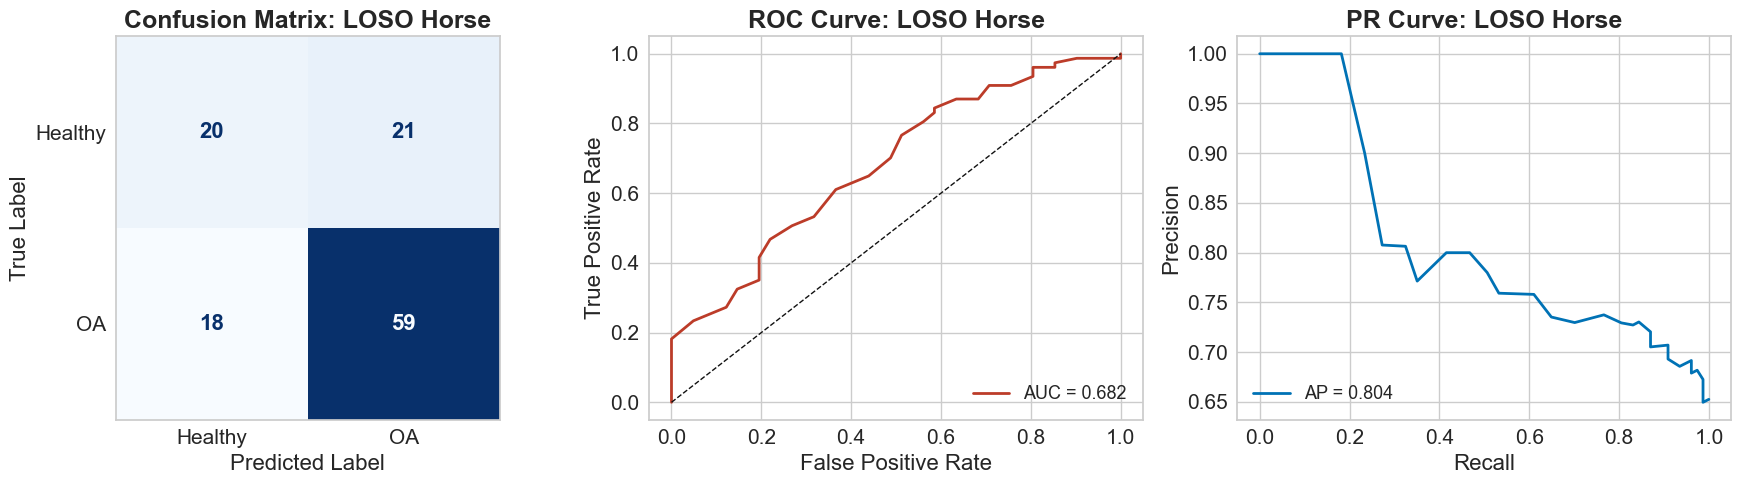

              precision    recall  f1-score   support

     Healthy       0.53      0.49      0.51        41
          OA       0.74      0.77      0.75        77

    accuracy                           0.67       118
   macro avg       0.63      0.63      0.63       118
weighted avg       0.66      0.67      0.67       118



In [10]:
# Step 3f: LOSO Horse — confusion matrix, ROC, and PR curves
y_true = (loso_eq_preds['Condition'] == 'OA').astype(int)
y_prob = loso_eq_preds['prediction_score_OA']
y_pred = (loso_eq_preds['prediction_label'] == 'OA').astype(int)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# CM
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(cm, display_labels=['Healthy', 'OA'])
disp.plot(ax=axes[0], cmap='Blues', colorbar=False)

axes[0].grid(False)

for text in disp.text_.ravel():
    text.set_fontsize(16)
    text.set_fontweight('bold')

# ROC
fpr, tpr, _ = roc_curve(y_true, y_prob)
roc_auc = auc(fpr, tpr)
axes[1].plot(fpr, tpr, color='#BC3C29', lw=2, label=f'AUC = {roc_auc:.3f}')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1)

axes[0].set_title('Confusion Matrix: LOSO Horse', fontsize=18, fontweight='bold')
axes[1].set_xlabel('False Positive Rate', fontsize=16)
axes[1].set_ylabel('True Positive Rate', fontsize=16)
axes[0].tick_params(labelsize=15)
axes[0].set_ylabel('True Label', fontsize=16)
axes[0].set_xlabel('Predicted Label', fontsize=16)
axes[1].set_title('ROC Curve: LOSO Horse', fontsize=18, fontweight='bold')
axes[1].legend(loc='lower right', fontsize=13)
axes[1].tick_params(labelsize=15)

# PR
precision, recall, _ = precision_recall_curve(y_true, y_prob)
ap = average_precision_score(y_true, y_prob)
axes[2].plot(recall, precision, color='#0072B5', lw=2, label=f'AP = {ap:.3f}')
axes[2].set_xlabel('Recall', fontsize=16)
axes[2].set_ylabel('Precision', fontsize=16)
axes[2].set_title('PR Curve: LOSO Horse', fontsize=18, fontweight='bold')
axes[2].legend(loc='lower left', fontsize=13)
axes[2].tick_params(labelsize=15)

plt.tight_layout()
plt.savefig('loso_horse_metrics.svg', dpi=300, bbox_inches='tight')
plt.show()

print(classification_report(y_true, y_pred, target_names=['Healthy', 'OA']))

#### Step 4a: LOSO Human

In [11]:
# Step 4a: LOSO Human
# Train on Dog + Horse, evaluate on all Human
train_subset_hu = df[df['Species'] != 'Human'].reset_index(drop=True)
eval_subset_hu = df[df['Species'] == 'Human'].reset_index(drop=True)
train_groups_hu = train_subset_hu['subject_id']

assert 'Human' not in train_subset_hu['Species'].values, "LEAKAGE: Human in training"
assert set(train_subset_hu['subject_id']) & set(eval_subset_hu['subject_id']) == set(), \
    "Subject overlap between train and eval"

print(f"Train set: {len(train_subset_hu)} samples (excluded Human)")
print(f"Eval set: {len(eval_subset_hu)} samples (Human only)\n")

setup(
    data=train_subset_hu,
    target='Condition',
    session_id=SEED,
    index=True,
    normalize=True,
    normalize_method='zscore',
    transformation=False,
    fix_imbalance=True,
    fix_imbalance_method='smote',
    fold_strategy=sgkf,
    fold=5,
    fold_groups=train_groups_hu,
    ignore_features=['subject_id', 'samples', 'Species'],
    remove_outliers=False,
    n_jobs=-1,
    verbose=True,
    train_size = 0.8
)
compare_models(sort='AUC', n_select=3, verbose=True)

Train set: 177 samples (excluded Human)
Eval set: 46 samples (Human only)



,Description,Value
0,Session id,42
1,Target,Condition
2,Target type,Binary
3,Target mapping,"Healthy: 0, OA: 1"
4,Original data shape,"(177, 72)"
5,Transformed data shape,"(238, 69)"
6,Transformed train set shape,"(202, 69)"
7,Transformed test set shape,"(36, 69)"
8,Ignore features,3
9,Numeric features,68


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
lr,Logistic Regression,0.8511,0.9107,0.8511,0.8558,0.8515,0.6372,0.6412,0.2733
et,Extra Trees Classifier,0.8227,0.9087,0.8227,0.8249,0.8040,0.5117,0.5420,0.0400
rf,Random Forest Classifier,0.8156,0.8971,0.8156,0.8108,0.8010,0.5100,0.5245,0.0433
svm,SVM - Linear Kernel,0.7730,0.8706,0.7730,0.7669,0.7635,0.4038,0.4143,0.0100
knn,K Neighbors Classifier,0.7234,0.8678,0.7234,0.8268,0.7352,0.4553,0.5122,0.0167
lightgbm,Light Gradient Boosting Machine,0.8440,0.8440,0.8440,0.8414,0.8380,0.5930,0.6013,0.0800
ada,Ada Boost Classifier,0.7730,0.8392,0.7730,0.7805,0.7726,0.4436,0.4507,0.0333
nb,Naive Bayes,0.7589,0.8249,0.7589,0.7971,0.7680,0.4716,0.4885,0.0167
ridge,Ridge Classifier,0.7660,0.8111,0.7660,0.7922,0.7705,0.4637,0.4779,0.0100
gbc,Gradient Boosting Classifier,0.8014,0.8107,0.8014,0.8078,0.7975,0.4990,0.5115,0.0567


[LogisticRegression(C=1.0, class_weight=None, dual=False, fit_intercept=True,
                    intercept_scaling=1, l1_ratio=None, max_iter=1000,
                    multi_class='auto', n_jobs=None, penalty='l2',
                    random_state=42, solver='lbfgs', tol=0.0001, verbose=0,
                    warm_start=False),
 ExtraTreesClassifier(bootstrap=False, ccp_alpha=0.0, class_weight=None,
                      criterion='gini', max_depth=None, max_features='sqrt',
                      max_leaf_nodes=None, max_samples=None,
                      min_impurity_decrease=0.0, min_samples_leaf=1,
                      min_samples_split=2, min_weight_fraction_leaf=0.0,
                      monotonic_cst=None, n_estimators=100, n_jobs=-1,
                      oob_score=False, random_state=42, verbose=0,
                      warm_start=False),
 RandomForestClassifier(bootstrap=True, ccp_alpha=0.0, class_weight=None,
                        criterion='gini', max_depth=None, max_f

#### Step 4b: Create and tune models

In [12]:
# Step 4b: Create and tune models
rf_hu = create_model('rf')
tuned_rf_hu = tune_model(rf_hu,
    optimize='AUC',
    n_iter=5,
    search_library='scikit-optimize',
    search_algorithm='bayesian',
    choose_better=True)

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.8936,0.8774,0.8936,0.8915,0.8921,0.7124,0.7135
1,0.8298,0.9242,0.8298,0.8298,0.8298,0.5747,0.5747
2,0.7234,0.8896,0.7234,0.7109,0.6812,0.2429,0.2852
Mean,0.8156,0.8971,0.8156,0.8108,0.8010,0.5100,0.5245
Std,0.0702,0.0198,0.0702,0.0749,0.0885,0.1971,0.1784


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.8085,0.8690,0.8085,0.8281,0.8149,0.5347,0.5412
1,0.8298,0.8348,0.8298,0.8298,0.8298,0.5747,0.5747
2,0.7660,0.8000,0.7660,0.7631,0.7419,0.3853,0.4186
Mean,0.8014,0.8346,0.8014,0.8070,0.7955,0.4982,0.5115
Std,0.0265,0.0282,0.0265,0.0310,0.0384,0.0815,0.0671


Fitting 3 folds for each of 1 candidates, totalling 3 fits
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Original model was better than the tuned model, hence it will be returned. NOTE: The display metrics are for the tuned model (not the original one).


#### Step 4c: 0.9 Sensitivity-fixed operating point thresholding

In [13]:
# Step 4c: Sensitivity-fixed threshold from grouped OOF predictions — Human LOSO
pipeline = get_config('pipeline')
full_pipeline = clone(pipeline)
full_pipeline.steps.append(('clf', clone(rf_hu)))

ignore_cols = ['subject_id', 'samples', 'Species', 'Condition']
X_all = train_subset_hu.drop(columns=ignore_cols).reset_index(drop=True)
y_all = train_subset_hu['Condition'].reset_index(drop=True)
g_all = train_subset_hu['subject_id'].reset_index(drop=True)

# Alignment checks
assert len(X_all) == len(y_all) == len(g_all) == 177
assert X_all.index.equals(y_all.index) and y_all.index.equals(g_all.index)
assert g_all.notna().all()
assert list(X_all.columns) == list(get_config('X_train').columns), "Feature columns differ from setup()"

# Build folds once; the same folds are used for the checks and the predictions
folds = list(sgkf.split(X_all, y_all, groups=g_all))

# Leakage checks on the folds actually used
validation_count = np.zeros(len(X_all), dtype=int)
for k, (tr, va) in enumerate(folds, start=1):
    overlap = set(g_all.iloc[tr]) & set(g_all.iloc[va])
    assert not overlap, f"Subject leakage in fold {k}: {overlap}"
    validation_count[va] += 1
assert np.all(validation_count == 1), "Each sample must be validated exactly once"

paired = g_all[g_all.str.contains('paired')].unique()
assert len(paired) == 0, f"Expected 0 paired subjects, found {len(paired)}"
print("Pipeline steps:", [n for n, _ in full_pipeline.steps])

# OOF predictions: full pipeline (impute -> SMOTE -> normalize -> RF) refit inside each fold
oof_proba = cross_val_predict(full_pipeline, X_all, y_all, cv=folds, method='predict_proba')
oa_col = list(np.unique(y_all)).index('OA')
oof_scores = oof_proba[:, oa_col]

# Threshold: highest threshold with OOF sensitivity >= 0.90 (maximizes specificity under the floor)
fpr, tpr, thresholds = roc_curve(y_all, oof_scores, pos_label='OA', drop_intermediate=False)
valid = tpr >= 0.90
if not valid.any():
    raise ValueError("No threshold achieves 0.90 sensitivity")
idx = np.argmax(valid)
chosen_threshold_hu = float(thresholds[idx])

# Verify directly against labels
pred = oof_scores >= chosen_threshold_hu
is_oa = (y_all == 'OA').values
sens = pred[is_oa].mean()
spec = (~pred[~is_oa]).mean()
assert sens >= 0.90, f"Sensitivity floor violated: {sens}"
assert np.isclose(sens, tpr[idx]), "Threshold and labels disagree"

print("OOF AUC:", auc(fpr, tpr))
print("Threshold:", chosen_threshold_hu)
print("OOF sensitivity:", sens)
print("OOF specificity:", spec)
print("Step 4c verified.")

Pipeline steps: ['label_encoding', 'numerical_imputer', 'categorical_imputer', 'balance', 'normalize', 'clean_column_names', 'clf']
OOF AUC: 0.9140157480314959
Threshold: 0.5
OOF sensitivity: 0.905511811023622
OOF specificity: 0.7
Step 4c verified.


#### Step 4d: SHAP plot

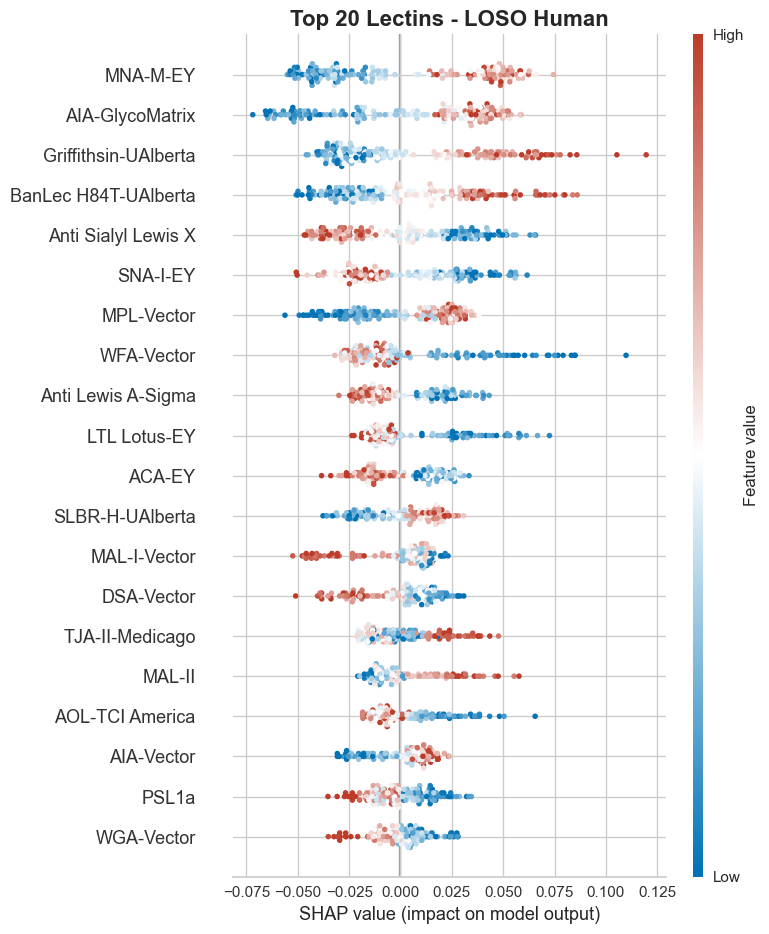

In [14]:
# Step 4d: SHAP plot
# 1. Get the transformed data, filtered to real rows only (no SMOTE synthetic rows)
X_train_transformed = get_config('X_train_transformed')
X_real = X_train_transformed.iloc[:len(train_subset_hu), :]

# 2. Extract the naked model 
model_for_shap = rf_hu.steps[-1][1] if hasattr(rf_hu, 'steps') else rf_hu

# 3. Initialize TreeExplainer
explainer = shap.TreeExplainer(model_for_shap)

# 4. Calculate SHAP values on real rows only
shap_vals_raw = explainer.shap_values(X_real, check_additivity=False)

# 5. Extract just the OA class
if isinstance(shap_vals_raw, list):
    shap_vals_oa = shap_vals_raw[1]
else:
    shap_vals_oa = shap_vals_raw[:, :, 1]

# 6. Top-20 SHAP plot setup
colors = ['#0072B5', 'white', '#BC3C29']
cmap = LinearSegmentedColormap.from_list("nejm_cmap", colors)
mean_abs_vals = np.abs(shap_vals_oa).mean(axis=0)
top20_idx = np.argsort(mean_abs_vals)[-20:][::-1]
X_top20 = X_real.iloc[:, top20_idx]
shap_vals_top20 = shap_vals_oa[:, top20_idx]

# 7. Plot
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_vals_top20, X_top20, plot_type="dot", cmap=cmap, show=False)
plt.title("Top 20 Lectins - LOSO Human", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('shap_top20_loso_human.svg', dpi=300, bbox_inches='tight')
plt.show()

#### Step 4e: LOSO prediction

In [15]:
# Step 4e: Finalize and evaluate Human LOSO
# Verify Human is completely excluded from the development population
assert 'Human' not in train_subset_hu['Species'].values
assert set(train_subset_hu['subject_id']).isdisjoint(
    set(eval_subset_hu['subject_id'])
)

# Finalize on all Dog + Horse data
final_rf_hu = finalize_model(rf_hu)

# Evaluate once on completely unseen Human data
loso_hu_preds = predict_model(
    final_rf_hu,
    data=eval_subset_hu,
    raw_score=True,
    probability_threshold = chosen_threshold_hu
)
print(loso_hu_preds[['Species', 'Condition', 'prediction_label',
                      'prediction_score_OA', 'prediction_score_Healthy']])

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Random Forest Classifier,0.8043,0.4972,0.8043,0.8435,0.7352,0.1481,0.2828


   Species Condition prediction_label  prediction_score_OA  \
0    Human   Healthy               OA                 0.90   
1    Human   Healthy               OA                 0.73   
2    Human   Healthy               OA                 0.81   
3    Human   Healthy               OA                 0.86   
4    Human   Healthy               OA                 0.86   
5    Human   Healthy               OA                 0.77   
6    Human   Healthy               OA                 0.74   
7    Human   Healthy          Healthy                 0.45   
8    Human   Healthy               OA                 0.80   
9    Human   Healthy               OA                 0.85   
10   Human        OA               OA                 0.74   
11   Human        OA               OA                 0.88   
12   Human        OA               OA                 0.79   
13   Human        OA               OA                 0.77   
14   Human        OA               OA                 0.88   
15   Hum

#### Step 4f: LOSO human — confusion matrix, ROC, and PR curves

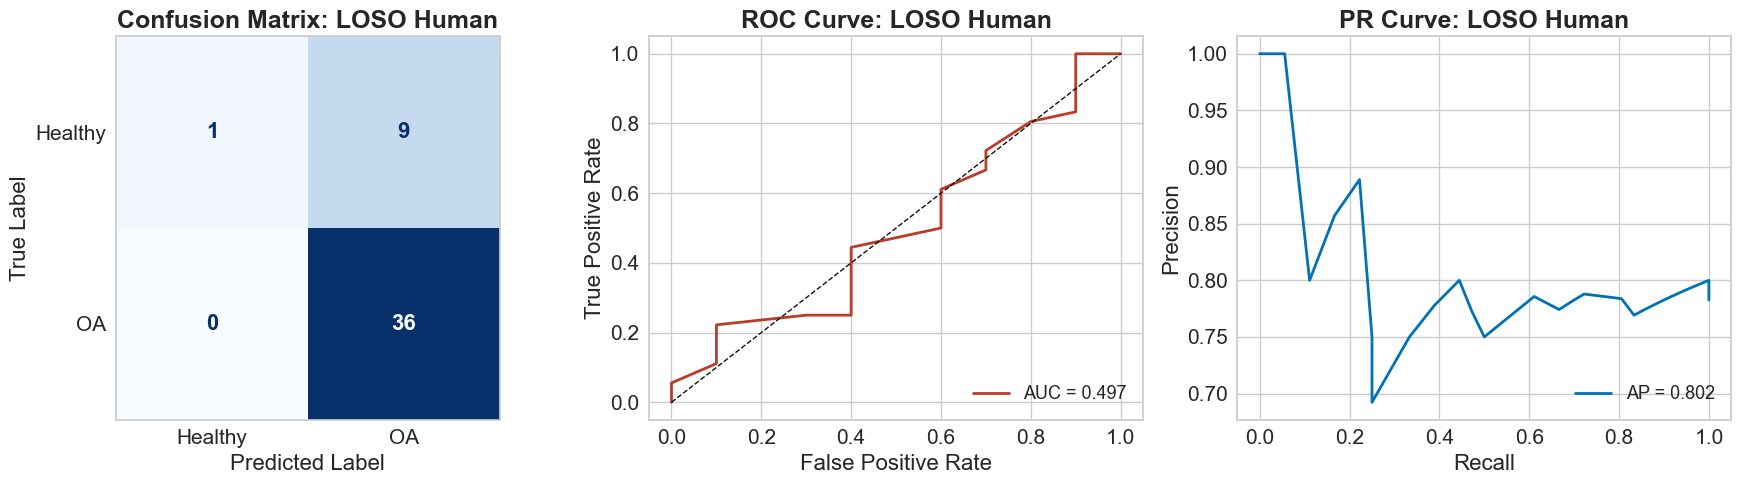

              precision    recall  f1-score   support

     Healthy       1.00      0.10      0.18        10
          OA       0.80      1.00      0.89        36

    accuracy                           0.80        46
   macro avg       0.90      0.55      0.54        46
weighted avg       0.84      0.80      0.74        46



In [16]:
# Step 4f: LOSO human — confusion matrix, ROC, and PR curves
y_true = (loso_hu_preds['Condition'] == 'OA').astype(int)
y_prob = loso_hu_preds['prediction_score_OA']
y_pred = (loso_hu_preds['prediction_label'] == 'OA').astype(int)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# CM
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(cm, display_labels=['Healthy', 'OA'])
disp.plot(ax=axes[0], cmap='Blues', colorbar=False)

axes[0].grid(False)

for text in disp.text_.ravel():
    text.set_fontsize(16)
    text.set_fontweight('bold')

# ROC
fpr, tpr, _ = roc_curve(y_true, y_prob)
roc_auc = auc(fpr, tpr)
axes[1].plot(fpr, tpr, color='#BC3C29', lw=2, label=f'AUC = {roc_auc:.3f}')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1)

axes[0].set_title('Confusion Matrix: LOSO Human', fontsize=18, fontweight='bold')
axes[1].set_xlabel('False Positive Rate', fontsize=16)
axes[1].set_ylabel('True Positive Rate', fontsize=16)
axes[0].tick_params(labelsize=15)
axes[0].set_ylabel('True Label', fontsize=16)
axes[0].set_xlabel('Predicted Label', fontsize=16)
axes[1].set_title('ROC Curve: LOSO Human', fontsize=18, fontweight='bold')
axes[1].legend(loc='lower right', fontsize=13)
axes[1].tick_params(labelsize=15)

# PR
precision, recall, _ = precision_recall_curve(y_true, y_prob)
ap = average_precision_score(y_true, y_prob)
axes[2].plot(recall, precision, color='#0072B5', lw=2, label=f'AP = {ap:.3f}')
axes[2].set_xlabel('Recall', fontsize=16)
axes[2].set_ylabel('Precision', fontsize=16)
axes[2].set_title('PR Curve: LOSO Human', fontsize=18, fontweight='bold')
axes[2].legend(loc='lower right', fontsize=13)
axes[2].tick_params(labelsize=15)

plt.tight_layout()
plt.savefig('loso_human_metrics.svg', dpi=300, bbox_inches='tight')
plt.show()

print(classification_report(y_true, y_pred, target_names=['Healthy', 'OA']))

#### Step 5a: LOSO Dog 

In [17]:
# Step 5a: LOSO Dog
# Train on Human + Horse, evaluate on all Dog
#I chose to use 80/20 split so to maximize training since it will be tested on filtered dog subjects
train_subset_ca = df[df['Species'] != 'Dog'].reset_index(drop=True)
eval_subset_ca = df[df['Species'] == 'Dog'].reset_index(drop=True)
train_groups_ca = train_subset_ca['subject_id']

assert 'Dog' not in train_subset_ca['Species'].values, "LEAKAGE: Dog in training"
assert set(train_subset_ca['subject_id']) & set(eval_subset_ca['subject_id']) == set(), \
    "Subject overlap between train and eval"

print(f"Train set: {len(train_subset_ca)} samples (excluded Dog)")
print(f"Eval set: {len(eval_subset_ca)} samples (Dog only)\n")

setup(
    data=train_subset_ca,
    target='Condition',
    session_id=SEED,
    index=True,
    normalize=True,
    normalize_method='zscore',
    transformation=False,
    fix_imbalance=True,
    fix_imbalance_method='smote',
    fold_strategy=sgkf,
    fold=5,
    fold_groups=train_groups_ca,
    ignore_features=['subject_id', 'samples', 'Species'],
    remove_outliers=False,
    n_jobs=-1,
    verbose=True,
    train_size = 0.8
)
compare_models(sort='AUC', n_select=3, verbose=True)

Train set: 164 samples (excluded Dog)
Eval set: 59 samples (Dog only)



,Description,Value
0,Session id,42
1,Target,Condition
2,Target type,Binary
3,Target mapping,"Healthy: 0, OA: 1"
4,Original data shape,"(164, 72)"
5,Transformed data shape,"(213, 69)"
6,Transformed train set shape,"(180, 69)"
7,Transformed test set shape,"(33, 69)"
8,Ignore features,3
9,Numeric features,68


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
rf,Random Forest Classifier,0.7481,0.8455,0.7481,0.7466,0.7469,0.4052,0.4058,0.0433
knn,K Neighbors Classifier,0.7100,0.8378,0.7100,0.7923,0.7196,0.4273,0.4711,0.0100
et,Extra Trees Classifier,0.8094,0.8369,0.8094,0.8110,0.7986,0.5161,0.5380,0.0400
lightgbm,Light Gradient Boosting Machine,0.7477,0.8173,0.7477,0.7367,0.7381,0.3794,0.3849,0.0733
gbc,Gradient Boosting Classifier,0.7252,0.8134,0.7252,0.7258,0.7245,0.3596,0.3610,0.0567
lr,Logistic Regression,0.7630,0.8029,0.7630,0.7891,0.7658,0.4767,0.4939,0.0100
ada,Ada Boost Classifier,0.7787,0.7962,0.7787,0.7913,0.7813,0.5009,0.5074,0.0267
svm,SVM - Linear Kernel,0.7169,0.7719,0.7169,0.7178,0.7132,0.3344,0.3404,0.0100
ridge,Ridge Classifier,0.7556,0.7206,0.7556,0.7695,0.7591,0.4519,0.4573,0.0100
nb,Naive Bayes,0.6795,0.6626,0.6795,0.6961,0.6850,0.2848,0.2877,0.0100


[RandomForestClassifier(bootstrap=True, ccp_alpha=0.0, class_weight=None,
                        criterion='gini', max_depth=None, max_features='sqrt',
                        max_leaf_nodes=None, max_samples=None,
                        min_impurity_decrease=0.0, min_samples_leaf=1,
                        min_samples_split=2, min_weight_fraction_leaf=0.0,
                        monotonic_cst=None, n_estimators=100, n_jobs=-1,
                        oob_score=False, random_state=42, verbose=0,
                        warm_start=False),
 KNeighborsClassifier(algorithm='auto', leaf_size=30, metric='minkowski',
                      metric_params=None, n_jobs=-1, n_neighbors=5, p=2,
                      weights='uniform'),
 ExtraTreesClassifier(bootstrap=False, ccp_alpha=0.0, class_weight=None,
                      criterion='gini', max_depth=None, max_features='sqrt',
                      max_leaf_nodes=None, max_samples=None,
                      min_impurity_decrease=0.0, min_

#### Step 5b: Create and tune models

In [18]:
# Step 5b: Create and tune models
rf_ca = create_model('rf', groups=train_groups_ca)
tuned_rf_ca = tune_model(rf_ca,
    optimize='AUC',
    n_iter=5,
    search_library='scikit-optimize',
    search_algorithm='bayesian',
    choose_better=True, groups=train_groups_ca)

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7500,0.8555,0.7500,0.7438,0.7465,0.3529,0.3536
1,0.7500,0.8226,0.7500,0.7552,0.7522,0.4346,0.4352
2,0.7442,0.8583,0.7442,0.7407,0.7420,0.4281,0.4286
Mean,0.7481,0.8455,0.7481,0.7466,0.7469,0.4052,0.4058
Std,0.0027,0.0162,0.0027,0.0062,0.0042,0.0370,0.0370


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.8409,0.8802,0.8409,0.8375,0.8387,0.5882,0.5893
1,0.7727,0.7881,0.7727,0.7833,0.7764,0.4954,0.4980
2,0.7907,0.8619,0.7907,0.7945,0.7922,0.5463,0.5470
Mean,0.8014,0.8434,0.8014,0.8051,0.8024,0.5433,0.5447
Std,0.0289,0.0398,0.0289,0.0233,0.0264,0.0380,0.0373


Fitting 3 folds for each of 1 candidates, totalling 3 fits
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Original model was better than the tuned model, hence it will be returned. NOTE: The display metrics are for the tuned model (not the original one).


#### Step 5c: 0.9 Sensitivity-fixed operating point thresholding

In [19]:
# Step 5c: Sensitivity-fixed threshold from grouped OOF predictions — Dog LOSO
pipeline = get_config('pipeline')
full_pipeline = clone(pipeline)
full_pipeline.steps.append(('clf', clone(rf_ca)))

ignore_cols = ['subject_id', 'samples', 'Species', 'Condition']
X_all = train_subset_ca.drop(columns=ignore_cols).reset_index(drop=True)
y_all = train_subset_ca['Condition'].reset_index(drop=True)
g_all = train_subset_ca['subject_id'].reset_index(drop=True)

# Alignment checks
assert len(X_all) == len(y_all) == len(g_all) == 164
assert X_all.index.equals(y_all.index) and y_all.index.equals(g_all.index)
assert g_all.notna().all()
assert list(X_all.columns) == list(get_config('X_train').columns), "Feature columns differ from setup()"

# Build folds once; the same folds are used for the checks and the predictions
folds = list(sgkf.split(X_all, y_all, groups=g_all))

# Leakage checks on the folds actually used
validation_count = np.zeros(len(X_all), dtype=int)
for k, (tr, va) in enumerate(folds, start=1):
    overlap = set(g_all.iloc[tr]) & set(g_all.iloc[va])
    assert not overlap, f"Subject leakage in fold {k}: {overlap}"
    validation_count[va] += 1
assert np.all(validation_count == 1), "Each sample must be validated exactly once"

paired = g_all[g_all.str.contains('paired')].unique()
assert len(paired) == 10, f"Expected 10 paired subjects, found {len(paired)}"
print("Pipeline steps:", [n for n, _ in full_pipeline.steps])

# OOF predictions: full pipeline (impute -> SMOTE -> normalize -> RF) refit inside each fold
oof_proba = cross_val_predict(full_pipeline, X_all, y_all, cv=folds, method='predict_proba')
oa_col = list(np.unique(y_all)).index('OA')
oof_scores = oof_proba[:, oa_col]

# Threshold: highest threshold with OOF sensitivity >= 0.90 (maximizes specificity under the floor)
fpr, tpr, thresholds = roc_curve(y_all, oof_scores, pos_label='OA', drop_intermediate=False)
valid = tpr >= 0.90
if not valid.any():
    raise ValueError("No threshold achieves 0.90 sensitivity")
idx = np.argmax(valid)
chosen_threshold_ca = float(thresholds[idx])

# Verify directly against labels
pred = oof_scores >= chosen_threshold_ca
is_oa = (y_all == 'OA').values
sens = pred[is_oa].mean()
spec = (~pred[~is_oa]).mean()
assert sens >= 0.90, f"Sensitivity floor violated: {sens}"
assert np.isclose(sens, tpr[idx]), "Threshold and labels disagree"

print("OOF AUC:", auc(fpr, tpr))
print("Threshold:", chosen_threshold_ca)
print("OOF sensitivity:", sens)
print("OOF specificity:", spec)
print("Step 5c verified.")

Pipeline steps: ['label_encoding', 'numerical_imputer', 'categorical_imputer', 'balance', 'normalize', 'clean_column_names', 'clf']
OOF AUC: 0.8440048585806003
Threshold: 0.48
OOF sensitivity: 0.911504424778761
OOF specificity: 0.5294117647058824
Step 5c verified.


#### Step 5d: SHAP plot

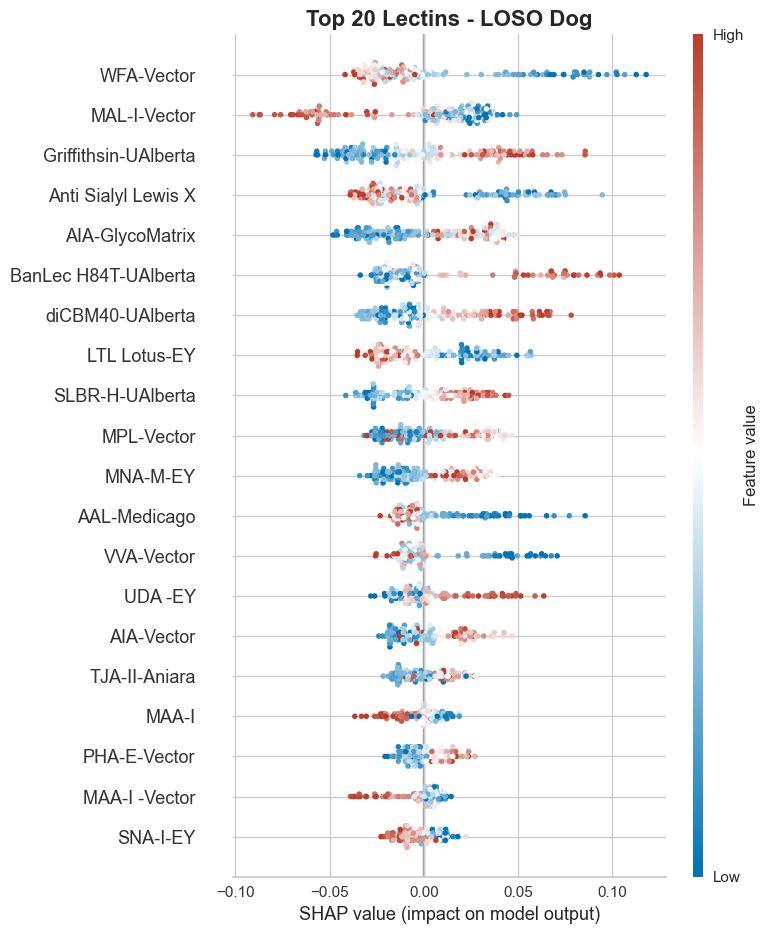

In [20]:
# Step 5d: SHAP plot

# 1. Get the transformed data, filtered to real rows only (no SMOTE synthetic rows)
X_train_transformed = get_config('X_train_transformed')
X_real = X_train_transformed.iloc[:len(train_subset_ca), :]

# 2. Extract the model
model_for_shap = rf_ca.steps[-1][1] if hasattr(rf_ca, 'steps') else rf_ca

# 3. Initialize TreeExplainer
explainer = shap.TreeExplainer(model_for_shap)

# 4. Calculate SHAP values on real rows only
shap_vals_raw = explainer.shap_values(X_real, check_additivity=False)

# 5. Extract just the OA class
if isinstance(shap_vals_raw, list):
    shap_vals_oa = shap_vals_raw[1]
else:
    shap_vals_oa = shap_vals_raw[:, :, 1]

# 6. Top-20 SHAP plot setup
colors = ['#0072B5', 'white', '#BC3C29']
cmap = LinearSegmentedColormap.from_list("nejm_cmap", colors)
mean_abs_vals = np.abs(shap_vals_oa).mean(axis=0)
top20_idx = np.argsort(mean_abs_vals)[-20:][::-1]
X_top20 = X_real.iloc[:, top20_idx]
shap_vals_top20 = shap_vals_oa[:, top20_idx]

# 7. Plot
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_vals_top20, X_top20, plot_type="dot", cmap=cmap, show=False)
plt.title("Top 20 Lectins - LOSO Dog", fontsize=16, fontweight='bold')
plt.savefig('shap_top20_loso_dog.svg', dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.show()

#### Step 5e: LOSO prediction

In [21]:
# Step 5e: LOSO prediction
# Verify Dog is completely excluded from the development population
assert 'Dog' not in train_subset_ca['Species'].values
assert set(train_subset_ca['subject_id']).isdisjoint(
    set(eval_subset_ca['subject_id'])
)

# Finalize on all Human + Horse data
final_rf_ca = finalize_model(rf_ca)

# Evaluate once on completely unseen Dog data
loso_ca_preds = predict_model(
    final_rf_ca,
    data=eval_subset_ca,
    raw_score=True,
    probability_threshold=chosen_threshold_ca
)

print(loso_ca_preds[['Species', 'Condition', 'prediction_label',
                      'prediction_score_OA', 'prediction_score_Healthy']])

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Random Forest Classifier,0.8475,0.8333,0.8475,0.7182,0.7775,0.0000,0.0000


   Species Condition prediction_label  prediction_score_OA  \
0      Dog   Healthy               OA                 0.59   
1      Dog   Healthy               OA                 0.74   
2      Dog   Healthy               OA                 0.73   
3      Dog   Healthy               OA                 0.75   
4      Dog   Healthy               OA                 0.75   
5      Dog   Healthy               OA                 0.61   
6      Dog   Healthy               OA                 0.72   
7      Dog   Healthy               OA                 0.71   
8      Dog   Healthy               OA                 0.67   
9      Dog        OA               OA                 0.80   
10     Dog        OA               OA                 0.86   
11     Dog        OA               OA                 0.84   
12     Dog        OA               OA                 0.55   
13     Dog        OA               OA                 0.80   
14     Dog        OA               OA                 0.79   
15     D

#### Step 5f: LOSO dog — confusion matrix, ROC, and PR curves

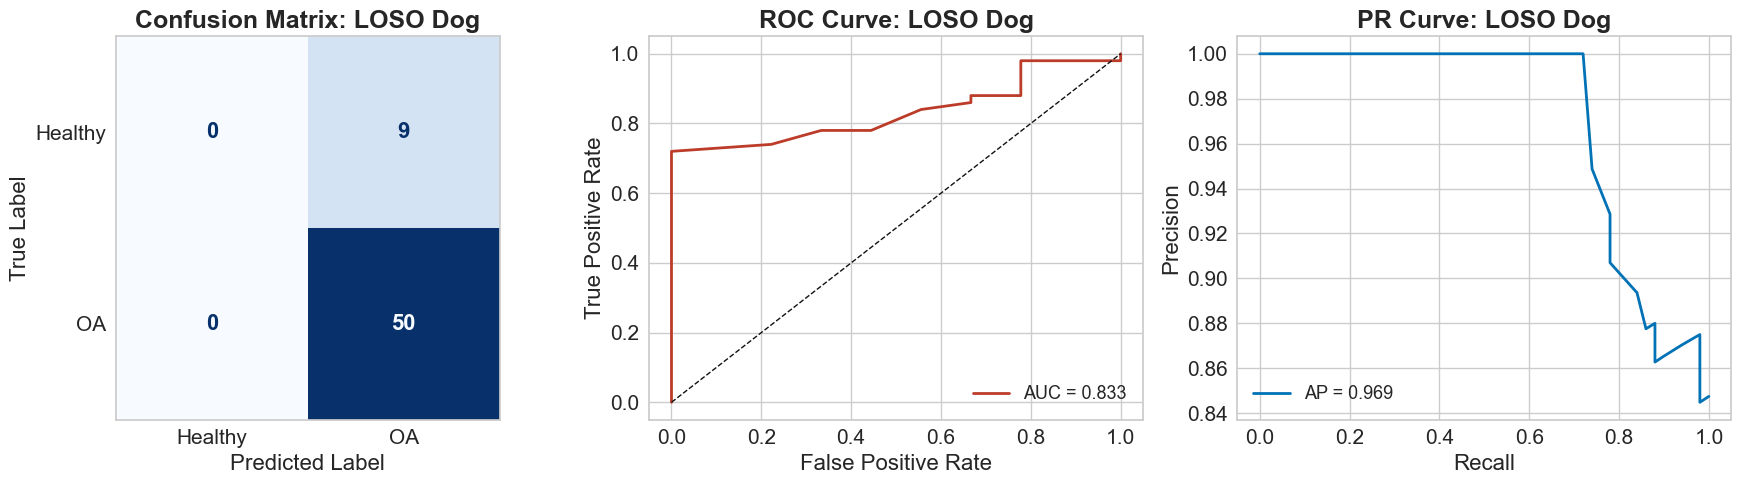

              precision    recall  f1-score   support

     Healthy       0.00      0.00      0.00         9
          OA       0.85      1.00      0.92        50

    accuracy                           0.85        59
   macro avg       0.42      0.50      0.46        59
weighted avg       0.72      0.85      0.78        59



In [22]:
# Step 5f: LOSO dog — confusion matrix, ROC, and PR curves
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, auc, precision_recall_curve, 
                             average_precision_score, classification_report)

y_true = (loso_ca_preds['Condition'] == 'OA').astype(int)
y_prob = loso_ca_preds['prediction_score_OA']
y_pred = (loso_ca_preds['prediction_label'] == 'OA').astype(int)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# CM
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(cm, display_labels=['Healthy', 'OA'])
disp.plot(ax=axes[0], cmap='Blues', colorbar=False)

axes[0].grid(False)

for text in disp.text_.ravel():
    text.set_fontsize(16)
    text.set_fontweight('bold')

# Make the numbers inside the cells bigger
for text in disp.text_.ravel():
    text.set_fontsize(16)
    text.set_fontweight('bold')

# ROC
fpr, tpr, _ = roc_curve(y_true, y_prob)
roc_auc = auc(fpr, tpr)
axes[1].plot(fpr, tpr, color='#BC3C29', lw=2, label=f'AUC = {roc_auc:.3f}')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1)

axes[0].set_title('Confusion Matrix: LOSO Dog', fontsize=18, fontweight='bold')
axes[1].set_xlabel('False Positive Rate', fontsize=16)
axes[1].set_ylabel('True Positive Rate', fontsize=16)
axes[0].tick_params(labelsize=15)
axes[0].set_ylabel('True Label', fontsize=16)
axes[0].set_xlabel('Predicted Label', fontsize=16)
axes[1].set_title('ROC Curve: LOSO Dog', fontsize=18, fontweight='bold')
axes[1].legend(loc='lower right', fontsize=13)
axes[1].tick_params(labelsize=15)

# PR
precision, recall, _ = precision_recall_curve(y_true, y_prob)
ap = average_precision_score(y_true, y_prob)
axes[2].plot(recall, precision, color='#0072B5', lw=2, label=f'AP = {ap:.3f}')
axes[2].set_xlabel('Recall', fontsize=16)
axes[2].set_ylabel('Precision', fontsize=16)
axes[2].set_title('PR Curve: LOSO Dog', fontsize=18, fontweight='bold')
axes[2].legend(loc='lower left', fontsize=13)
axes[2].tick_params(labelsize=15)

plt.tight_layout()
plt.savefig('loso_dog_metrics.svg', dpi=300, bbox_inches='tight')
plt.show()

print(classification_report(y_true, y_pred, target_names=['Healthy', 'OA']))

#### Step 6: LOSO Summary

In [23]:
# Step 6: LOSO Summary

rows = []
for name, preds in [('Horse', loso_eq_preds), ('Human', loso_hu_preds), ('Dog', loso_ca_preds)]:
    y_true = (preds['Condition'] == 'OA').astype(int)
    y_prob = preds['prediction_score_OA']
    y_pred = (preds['prediction_label'] == 'OA').astype(int)
    
    rows.append({
        'Held-out Species': name,
        'N Eval': len(preds),
        'N OA': int(y_true.sum()),
        'N Healthy': int((1 - y_true).sum()),
        'ROC AUC': round(roc_auc_score(y_true, y_prob), 3),
        'Sensitivity': round(recall_score(y_true, y_pred), 3),
        'Specificity': round(recall_score(1 - y_true, 1 - y_pred), 3),
        'Precision': round(precision_score(y_true, y_pred, zero_division=0), 3),
    })

summary = pd.DataFrame(rows)
print("LOSO Cross-Species Generalization Summary")
print("=" * 75)
print("Threshold: 0.9 sensitivity")
print("Species excluded from: preprocessing, model selection, and evaluation threshold")

print("=" * 75)
print()
print(summary.to_string(index=False))

LOSO Cross-Species Generalization Summary
Threshold: 0.9 sensitivity
Species excluded from: preprocessing, model selection, and evaluation threshold

Held-out Species  N Eval  N OA  N Healthy  ROC AUC  Sensitivity  Specificity  Precision
           Horse     118    77         41    0.682        0.766        0.488      0.738
           Human      46    36         10    0.497        1.000        0.100      0.800
             Dog      59    50          9    0.833        1.000        0.000      0.847
